# CastVision — Inspección automática de piezas fundidas con Visión Artificial Clásica

**Entrega 3 · Visión Artificial · ITM** · Docente: Cristian Mateo Hernández González
**Autor:** Sebastián Gallego

**Problema:** una pieza metálica fundida con una grieta o un poro que llega al cliente cuesta mucho más que detectarla en planta.
**Solución:** clasificar cada pieza como *OK* o *Defectuosa* con el pipeline clásico visto en clase (sin Deep Learning):

1. Extracción de características: **HOG, LBP, GLCM** y su **fusión**
2. Normalización: **Z-score**
3. Clasificación: **k-NN, SVM, Random Forest**

**Dataset:** [Real-life Industrial Dataset of Casting Product (Kaggle)](https://www.kaggle.com/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product).

### Cómo usar este notebook
1. Descarga el dataset de Kaggle y descomprímelo para que quede en `casting_data/casting_data/` junto a este notebook (o cambia `RUTA_DATASET` en la celda de configuración).
2. Ejecuta todas las celdas en orden (*Kernel → Restart & Run All*).
3. Para probar una pieza nueva, ve directo a la sección **9. Usar el modelo** (necesita que ya exista `modelo_castvision.joblib`).

## 0. Librerías y configuración

In [1]:
import os
import time
import warnings
import joblib
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, make_scorer)

# Descriptores de características (scikit-image)
from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops

warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
# ---------------- CONFIGURACIÓN (lo único que normalmente hay que tocar) ----------------
RUTA_DATASET = "casting_data/casting_data"   # carpeta que contiene train/ y test/
N_POR_CLASE = 1000                           # imágenes por clase (None = todas)
TAMANO = (128, 128)                          # tamaño al que se redimensionan las piezas
SEMILLA = 42                                 # para que los resultados sean reproducibles
CLASES = {0: "Defectuosa", 1: "OK"}          # etiqueta numérica -> nombre

## 1. Carga del dataset
Se leen las imágenes de `def_front` (piezas **defectuosas**, etiqueta 0) y `ok_front` (piezas **buenas**, etiqueta 1).

In [3]:
carpetas_defectuosa = [os.path.join(RUTA_DATASET, "train", "def_front"),
                       os.path.join(RUTA_DATASET, "test", "def_front")]
carpetas_ok = [os.path.join(RUTA_DATASET, "train", "ok_front"),
               os.path.join(RUTA_DATASET, "test", "ok_front")]

extensiones = (".jpg", ".jpeg", ".png", ".bmp")


def cargar_imagenes_validas(carpetas, n=None):
    """Lee las imágenes de una lista de carpetas (en RGB) hasta completar n."""
    imgs = []
    for carpeta in carpetas:
        archivos = sorted(f for f in os.listdir(carpeta) if f.lower().endswith(extensiones))
        for f in archivos:
            img = cv2.imread(os.path.join(carpeta, f))
            if img is not None:
                imgs.append(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
            if n is not None and len(imgs) == n:
                return imgs
    return imgs


defectuosa_imgs = cargar_imagenes_validas(carpetas_defectuosa, N_POR_CLASE)
ok_imgs = cargar_imagenes_validas(carpetas_ok, N_POR_CLASE)
print(f"Piezas DEFECTUOSAS cargadas: {len(defectuosa_imgs)}")
print(f"Piezas OK cargadas: {len(ok_imgs)}")

Piezas DEFECTUOSAS cargadas: 1000
Piezas OK cargadas: 1000


## 2. Normalización de imágenes y partición Train / Validación
Cada imagen se redimensiona a 128×128 y se escala a [0, 1]. Luego se separa 70 % para entrenar y 30 % para validar, manteniendo la misma proporción de cada clase (`stratify`).

Train: (1400, 128, 128, 3) | Validación: (600, 128, 128, 3)


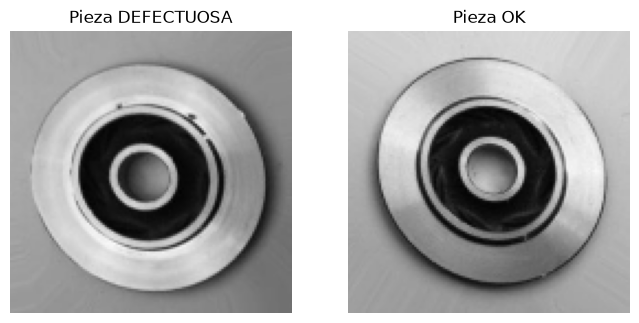

In [4]:
def normalizar_imagenes(imgs, size=TAMANO):
    out = []
    for img in imgs:
        out.append(cv2.resize(img, size).astype("float32") / 255.0)
    return np.array(out)


defectuosa_norm = normalizar_imagenes(defectuosa_imgs)
ok_norm = normalizar_imagenes(ok_imgs)

X = np.concatenate((defectuosa_norm, ok_norm), axis=0)
y = np.concatenate((np.zeros(len(defectuosa_norm)), np.ones(len(ok_norm))), axis=0)  # 0 = defectuosa, 1 = OK

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.3, random_state=SEMILLA, stratify=y)
print(f"Train: {X_train.shape} | Validación: {X_val.shape}")

# Una pieza de cada clase para las visualizaciones
idx_def = np.where(y_train == 0)[0][0]
idx_ok = np.where(y_train == 1)[0][0]
img_def_gray = cv2.cvtColor((X_train[idx_def] * 255).astype("uint8"), cv2.COLOR_RGB2GRAY)
img_ok_gray = cv2.cvtColor((X_train[idx_ok] * 255).astype("uint8"), cv2.COLOR_RGB2GRAY)

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1); plt.imshow(X_train[idx_def]); plt.title("Pieza DEFECTUOSA"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(X_train[idx_ok]); plt.title("Pieza OK"); plt.axis("off")
plt.show()

## 3. Extracción de características
Se transforma cada imagen en un vector de números (su "firma") que el clasificador puede comparar.

| Descriptor | Qué describe | Tamaño del vector |
|---|---|---|
| **HOG** | Dirección de los bordes → forma / silueta | 8100 |
| **LBP** | Micro-textura local | 10 |
| **GLCM** | Relación estadística entre píxeles vecinos → textura de superficie | 48 |

### 3.1 HOG — Histogram of Oriented Gradients

HOG  -> Train: (1400, 8100) | Validación: (600, 8100)


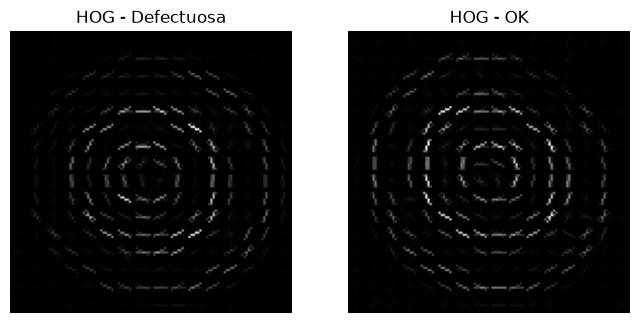

In [5]:
def extraer_hog(imagenes):
    feats = []
    for img in imagenes:
        gris = cv2.cvtColor((img * 255).astype("uint8"), cv2.COLOR_RGB2GRAY)
        feats.append(hog(gris, orientations=9, pixels_per_cell=(8, 8),
                         cells_per_block=(2, 2), block_norm="L2-Hys", visualize=False))
    return np.array(feats)


X_train_hog = extraer_hog(X_train)
X_val_hog = extraer_hog(X_val)
print(f"HOG  -> Train: {X_train_hog.shape} | Validación: {X_val_hog.shape}")

_, hog_def_vis = hog(img_def_gray, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)
_, hog_ok_vis = hog(img_ok_gray, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1); plt.imshow(hog_def_vis, cmap="gray"); plt.title("HOG - Defectuosa"); plt.axis("off")
plt.subplot(1, 2, 2); plt.imshow(hog_ok_vis, cmap="gray"); plt.title("HOG - OK"); plt.axis("off")
plt.show()

### 3.2 LBP — Local Binary Patterns

LBP  -> Train: (1400, 10) | Validación: (600, 10)


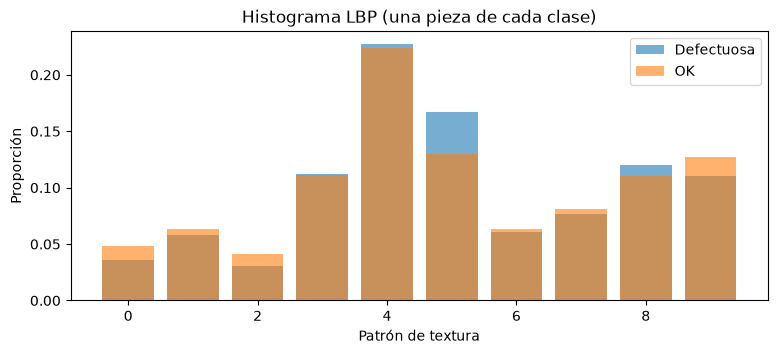

In [6]:
def extraer_lbp(imagenes, P=8, R=1):
    feats = []
    for img in imagenes:
        gris = cv2.cvtColor((img * 255).astype("uint8"), cv2.COLOR_RGB2GRAY)
        lbp = local_binary_pattern(gris, P=P, R=R, method="uniform")
        hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, P + 3), range=(0, P + 2))
        hist = hist.astype("float32")
        hist /= (hist.sum() + 1e-7)          # proporciones, no conteos
        feats.append(hist)
    return np.array(feats)


X_train_lbp = extraer_lbp(X_train)
X_val_lbp = extraer_lbp(X_val)
print(f"LBP  -> Train: {X_train_lbp.shape} | Validación: {X_val_lbp.shape}")

plt.figure(figsize=(9, 3.5))
plt.bar(range(X_train_lbp.shape[1]), X_train_lbp[idx_def], alpha=0.6, label="Defectuosa")
plt.bar(range(X_train_lbp.shape[1]), X_train_lbp[idx_ok], alpha=0.6, label="OK")
plt.title("Histograma LBP (una pieza de cada clase)"); plt.xlabel("Patrón de textura"); plt.ylabel("Proporción")
plt.legend(); plt.show()

### 3.3 GLCM — Matriz de co-ocurrencia de niveles de gris

In [7]:
def extraer_glcm(imagenes, distances=(1, 3), angles=(0, np.pi / 4, np.pi / 2, 3 * np.pi / 4)):
    feats = []
    propiedades = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]
    for img in imagenes:
        gris = cv2.cvtColor((img * 255).astype("uint8"), cv2.COLOR_RGB2GRAY)
        gris_q = (gris // 4).astype(np.uint8)       # 64 niveles de gris para acelerar el cálculo
        glcm = graycomatrix(gris_q, distances=list(distances), angles=list(angles),
                            levels=64, symmetric=True, normed=True)
        vector = []
        for p in propiedades:
            vector.extend(graycoprops(glcm, p).ravel())
        feats.append(vector)
    return np.array(feats)


X_train_glcm = extraer_glcm(X_train)
X_val_glcm = extraer_glcm(X_val)
print(f"GLCM -> Train: {X_train_glcm.shape} | Validación: {X_val_glcm.shape}")

GLCM -> Train: (1400, 48) | Validación: (600, 48)


## 4. Normalización Z-score y fusión de descriptores
Cada característica se transforma para tener **media 0 y desviación 1**, de modo que ningún descriptor domine solo por tener números más grandes. El escalador se ajusta **solo con Train** y se aplica a Validación (así no se "filtra" información de validación).
La **fusión** concatena HOG + LBP + GLCM (8100 + 10 + 48 = 8158 características).

In [8]:
X_train_fusion = np.hstack((X_train_hog, X_train_lbp, X_train_glcm))
X_val_fusion = np.hstack((X_val_hog, X_val_lbp, X_val_glcm))


def escalar(Xtr, Xva):
    sc = StandardScaler()
    return sc.fit_transform(Xtr), sc.transform(Xva)


X_train_hog_sc, X_val_hog_sc = escalar(X_train_hog, X_val_hog)
X_train_lbp_sc, X_val_lbp_sc = escalar(X_train_lbp, X_val_lbp)
X_train_glcm_sc, X_val_glcm_sc = escalar(X_train_glcm, X_val_glcm)
X_train_fusion_sc, X_val_fusion_sc = escalar(X_train_fusion, X_val_fusion)

print(f"Fusión -> Train: {X_train_fusion_sc.shape} | media={X_train_fusion_sc.mean():.4f} | desviación={X_train_fusion_sc.std():.4f}")

Fusión -> Train: (1400, 8158) | media=-0.0000 | desviación=1.0000


## 5. Benchmark: 3 clasificadores × 4 descriptores
Se entrenan 12 combinaciones y se mide Accuracy, Precision, Recall, F1 y tiempo.
Las métricas se calculan sobre la clase **Defectuosa** (`pos_label=0`), porque en control de calidad lo que importa es **cuántos defectos reales detectamos** (Recall) y no dejar pasar ninguno.

In [9]:
conjuntos = {
    "HOG": (X_train_hog_sc, X_val_hog_sc),
    "LBP": (X_train_lbp_sc, X_val_lbp_sc),
    "GLCM": (X_train_glcm_sc, X_val_glcm_sc),
    "FUSIÓN (HOG+LBP+GLCM)": (X_train_fusion_sc, X_val_fusion_sc),
}

modelos = {
    "k-NN (k=5)": KNeighborsClassifier(n_neighbors=5, metric="euclidean"),
    "SVM (RBF)": SVC(kernel="rbf", C=1.0, random_state=SEMILLA),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=SEMILLA, n_jobs=-1),
}

resultados = []
for nombre_desc, (Xtr, Xva) in conjuntos.items():
    for nombre_modelo, modelo_base in modelos.items():
        modelo_i = clone(modelo_base)
        t0 = time.time()
        modelo_i.fit(Xtr, y_train)
        y_pred = modelo_i.predict(Xva)
        t_total = time.time() - t0
        resultados.append({
            "Descriptor": nombre_desc,
            "Modelo": nombre_modelo,
            "Dimensiones": Xtr.shape[1],
            "Accuracy": accuracy_score(y_val, y_pred),
            "Precision (defectuosa)": precision_score(y_val, y_pred, pos_label=0, zero_division=0),
            "Recall (defectuosa)": recall_score(y_val, y_pred, pos_label=0),
            "F1-Score (defectuosa)": f1_score(y_val, y_pred, pos_label=0, zero_division=0),
            "Tiempo (s)": t_total,
        })

df_resultados = pd.DataFrame(resultados)
os.makedirs("resultados", exist_ok=True)
df_resultados.to_csv("resultados/benchmark.csv", index=False)
df_resultados.round(3)

,Descriptor,Modelo,Dimensiones,Accuracy,Precision (defectuosa),Recall (defectuosa),F1-Score (defectuosa),Tiempo (s)
0,HOG,k-NN (k=5),8100,0.690,0.975,0.390,0.557,0.540
1,HOG,SVM (RBF),8100,0.963,0.989,0.937,0.962,20.164
2,HOG,Random Forest,8100,0.880,0.901,0.853,0.877,3.903
3,LBP,k-NN (k=5),10,0.777,0.814,0.717,0.762,0.021
4,LBP,SVM (RBF),10,0.788,0.808,0.757,0.781,0.140
5,LBP,Random Forest,10,0.793,0.826,0.743,0.782,0.441
6,GLCM,k-NN (k=5),48,0.932,0.985,0.877,0.928,0.012
7,GLCM,SVM (RBF),48,0.928,0.954,0.900,0.926,0.176
8,GLCM,Random Forest,48,0.972,0.990,0.953,0.971,0.474
9,FUSIÓN (HOG+LBP+GLCM),k-NN (k=5),8158,0.703,0.977,0.417,0.584,0.415


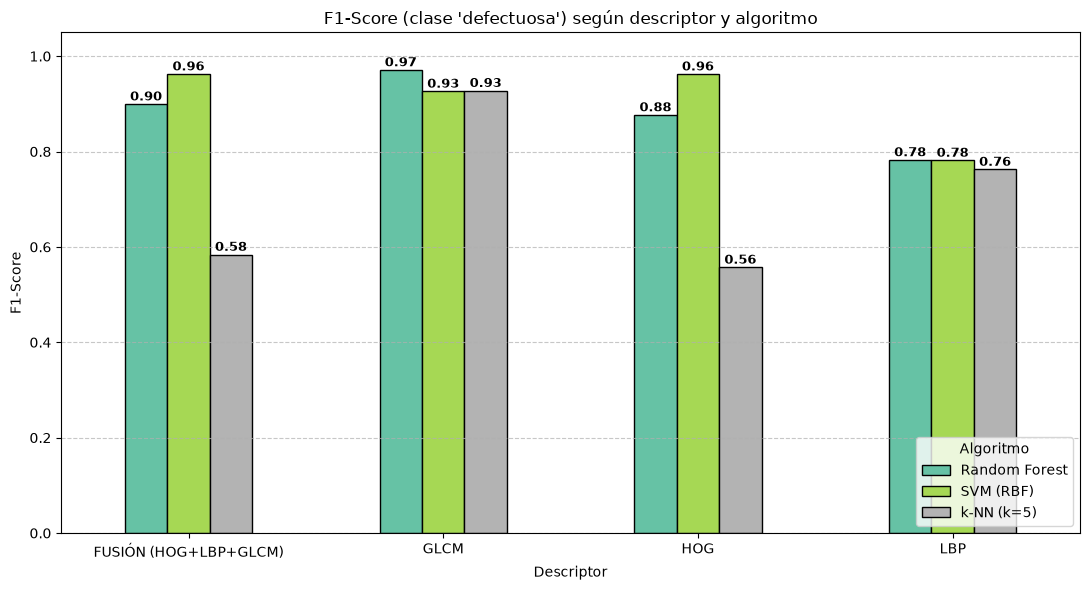

Mejor combinación: GLCM + Random Forest (F1=0.971, 48 características, 0.47 s)


In [10]:
df_pivot = df_resultados.pivot(index="Descriptor", columns="Modelo", values="F1-Score (defectuosa)")
ax = df_pivot.plot(kind="bar", figsize=(11, 6), colormap="Set2", edgecolor="black")
plt.title("F1-Score (clase 'defectuosa') según descriptor y algoritmo")
plt.ylabel("F1-Score"); plt.xlabel("Descriptor"); plt.ylim(0, 1.05); plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.7); plt.legend(title="Algoritmo", loc="lower right")
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="center", xytext=(0, 5), textcoords="offset points", fontsize=9, fontweight="bold")
plt.tight_layout()
plt.savefig("resultados/benchmark_f1.png", dpi=150)
plt.show()

mejor = df_resultados.sort_values("F1-Score (defectuosa)", ascending=False).iloc[0]
print(f"Mejor combinación: {mejor['Descriptor']} + {mejor['Modelo']} "
      f"(F1={mejor['F1-Score (defectuosa)']:.3f}, {mejor['Dimensiones']} características, {mejor['Tiempo (s)']:.2f} s)")

**Lectura de resultados.** El defecto de una pieza fundida (grieta, poro) es un cambio de **textura de superficie**, no de silueta: la pieza sigue siendo un disco. Por eso GLCM (textura) supera a HOG (formas), y lo hace con muchísimas menos características y casi sin costo de cómputo.

## 6. Validación del modelo ganador (GLCM + Random Forest)
Un solo reparto Train/Validación puede dar un resultado afortunado. Se revisa la **matriz de confusión** y se repite la evaluación con **validación cruzada de 5 particiones**.
El modelo se arma como `Pipeline` (Z-score + Random Forest) para que el escalado se ajuste dentro de cada partición.

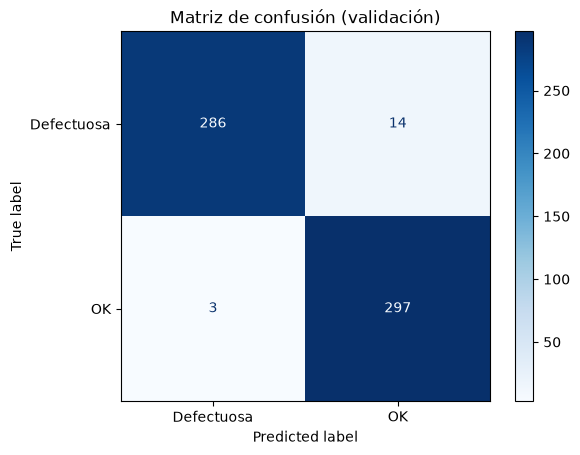

              precision    recall  f1-score   support

  Defectuosa      0.990     0.953     0.971       300
          OK      0.955     0.990     0.972       300

    accuracy                          0.972       600
   macro avg      0.972     0.972     0.972       600
weighted avg      0.972     0.972     0.972       600

Defectos detectados: 286 | Defectos que se escapan (falsos negativos): 14
Piezas buenas marcadas como defectuosas (falsas alarmas): 3


In [11]:
modelo_ganador = Pipeline([
    ("zscore", StandardScaler()),
    ("rf", RandomForestClassifier(n_estimators=100, random_state=SEMILLA, n_jobs=-1)),
])
modelo_ganador.fit(X_train_glcm, y_train)
y_pred = modelo_ganador.predict(X_val_glcm)

ConfusionMatrixDisplay.from_predictions(y_val, y_pred, display_labels=["Defectuosa", "OK"], cmap="Blues")
plt.title("Matriz de confusión (validación)")
plt.savefig("resultados/matriz_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

print(classification_report(y_val, y_pred, target_names=["Defectuosa", "OK"], digits=3))

cm = confusion_matrix(y_val, y_pred, labels=[0, 1])
tp, fn, fp, tn = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]   # 'positivo' = defectuosa
print(f"Defectos detectados: {tp} | Defectos que se escapan (falsos negativos): {fn}")
print(f"Piezas buenas marcadas como defectuosas (falsas alarmas): {fp}")

In [12]:
X_glcm_total = np.vstack([X_train_glcm, X_val_glcm])
y_total = np.concatenate([y_train, y_val])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
metricas = {
    "Recall (defectuosa)": make_scorer(recall_score, pos_label=0),
    "F1 (defectuosa)": make_scorer(f1_score, pos_label=0),
    "Accuracy": "accuracy",
}
cv_res = cross_validate(clone(modelo_ganador), X_glcm_total, y_total, cv=cv, scoring=metricas, n_jobs=-1)

for nombre in metricas:
    valores = cv_res[f"test_{nombre}"]
    print(f"{nombre:22s}: {valores.mean():.3f} ± {valores.std():.3f}   (por partición: {np.round(valores, 3)})")

Recall (defectuosa)   : 0.968 ± 0.005   (por partición: [0.96  0.975 0.965 0.97  0.97 ])
F1 (defectuosa)       : 0.974 ± 0.006   (por partición: [0.977 0.977 0.963 0.98  0.975])
Accuracy              : 0.974 ± 0.006   (por partición: [0.978 0.978 0.962 0.98  0.975])


## 7. Métricas de negocio (estimación ilustrativa)
Traducimos Recall y falsas alarmas a pesos colombianos (COP).
> ⚠️ Los **parámetros de planta y costos son supuestos ilustrativos**, no datos reales de una empresa: cámbialos en la celda para ver tu propio caso. Las tasas del modelo (Recall y falsas alarmas) sí vienen de la validación de arriba.
> En planta la tasa de defectos es baja (aquí 3 %), a diferencia del dataset (50 % / 50 %); por eso se usa la **tasa de falsas alarmas** y no la precisión del dataset.

In [13]:
# ---------- SUPUESTOS (editar) ----------
piezas_mes = 10_000          # producción mensual
tasa_defecto = 0.03          # 3 % de piezas defectuosas
costo_fuga = 500_000         # COP: devolución / garantía / reputación por pieza defectuosa que llega al cliente
costo_falsa_alarma = 20_000  # COP: re-inspección de una pieza buena marcada como defectuosa
recall_manual = 0.80         # inspección visual humana: detecta 80 % de los defectos
fpr_manual = 0.02            # inspección visual humana: 2 % de falsas alarmas

# ---------- Tasas medidas del modelo ----------
recall_modelo = tp / (tp + fn)
fpr_modelo = fp / (fp + tn)


def costo_mensual(recall, fpr):
    defectuosas = piezas_mes * tasa_defecto
    buenas = piezas_mes - defectuosas
    fugas = defectuosas * (1 - recall)
    falsas = buenas * fpr
    return fugas, falsas, fugas * costo_fuga + falsas * costo_falsa_alarma


def cop(x):
    return "$" + f"{x:,.0f}".replace(",", ".") + " COP"


fugas_m, falsas_m, costo_m = costo_mensual(recall_manual, fpr_manual)
fugas_c, falsas_c, costo_c = costo_mensual(recall_modelo, fpr_modelo)

tabla = pd.DataFrame({
    "Inspección manual": [f"{recall_manual:.1%}", f"{fpr_manual:.1%}", round(fugas_m), round(falsas_m), cop(costo_m)],
    "CastVision": [f"{recall_modelo:.1%}", f"{fpr_modelo:.1%}", round(fugas_c), round(falsas_c), cop(costo_c)],
}, index=["Recall (defectos detectados)", "Falsas alarmas (tasa)", "Defectos que se escapan / mes",
          "Falsas alarmas / mes", "Costo mensual de calidad"])
display(tabla)
print(f"Ahorro estimado: {cop(costo_m - costo_c)} al mes  |  {cop((costo_m - costo_c) * 12)} al año")

,Inspección manual,CastVision
Recall (defectos detectados),80.0%,95.3%
Falsas alarmas (tasa),2.0%,1.0%
Defectos que se escapan / mes,60,14
Falsas alarmas / mes,194,97
Costo mensual de calidad,$33.880.000 COP,$8.940.000 COP


Ahorro estimado: $24.940.000 COP al mes  |  $299.280.000 COP al año


## 8. Guardar el modelo
Se guarda el `Pipeline` (Z-score + Random Forest sobre GLCM) en un solo archivo para poder usarlo sin volver a entrenar.

In [14]:
joblib.dump(modelo_ganador, "modelo_castvision.joblib")
print("Modelo guardado en modelo_castvision.joblib")

Modelo guardado en modelo_castvision.joblib


## 9. Usar el modelo con una pieza nueva
`predecir_pieza("ruta/a/foto.jpg")` devuelve si la pieza es **OK** o **DEFECTUOSA** y la confianza del modelo.

In [15]:
modelo = joblib.load("modelo_castvision.joblib")


def predecir_imagen(img_bgr, mostrar=True):
    """Clasifica una imagen (formato OpenCV, BGR) como OK o DEFECTUOSA."""
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_norm = cv2.resize(img_rgb, TAMANO).astype("float32") / 255.0   # mismo preprocesado del entrenamiento
    features = extraer_glcm(np.array([img_norm]))
    clase = int(modelo.predict(features)[0])
    confianza = float(modelo.predict_proba(features)[0][clase])
    if mostrar:
        plt.figure(figsize=(3.5, 3.5))
        plt.imshow(img_rgb); plt.axis("off")
        plt.title(f"{CLASES[clase].upper()} ({confianza:.0%})", color="green" if clase == 1 else "red")
        plt.show()
    return {"resultado": CLASES[clase].upper(), "confianza": confianza}


def predecir_pieza(ruta_imagen, mostrar=True):
    """Clasifica la imagen que está en `ruta_imagen`."""
    img = cv2.imread(ruta_imagen)
    if img is None:
        raise FileNotFoundError(f"No se pudo leer la imagen: {ruta_imagen}")
    return predecir_imagen(img, mostrar)

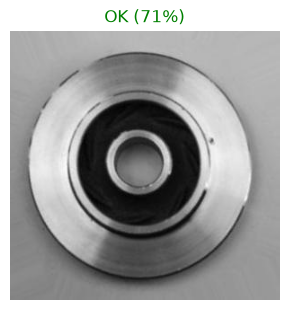

Archivo: cast_def_0_9997.jpeg -> {'resultado': 'OK', 'confianza': 0.71}


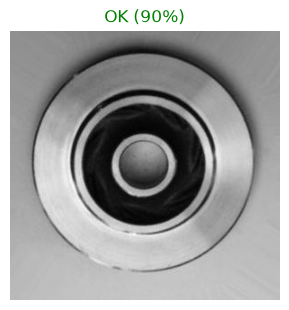

Archivo: cast_ok_0_9998.jpeg -> {'resultado': 'OK', 'confianza': 0.9}


In [16]:
# Demostración: la última imagen de cada carpeta (normalmente no usada en el entrenamiento)
for carpeta in (carpetas_defectuosa[0], carpetas_ok[0]):
    archivo = sorted(f for f in os.listdir(carpeta) if f.lower().endswith(extensiones))[-1]
    print(f"Archivo: {archivo} ->", predecir_pieza(os.path.join(carpeta, archivo)))

### Opción interactiva: subir una foto con un botón

In [17]:
try:
    import ipywidgets as widgets
    from IPython.display import display

    subir = widgets.FileUpload(accept="image/*", multiple=False, description="Subir foto")
    salida = widgets.Output()

    def al_subir(cambio):
        valor = subir.value
        archivos = list(valor.values()) if isinstance(valor, dict) else list(valor)
        if not archivos:
            return
        contenido = archivos[0]["content"]
        img = cv2.imdecode(np.frombuffer(bytes(contenido), np.uint8), cv2.IMREAD_COLOR)
        with salida:
            salida.clear_output()
            if img is None:
                print("No se pudo leer la imagen.")
            else:
                print(predecir_imagen(img))

    subir.observe(al_subir, names="value")
    display(subir, salida)
except ImportError:
    print("Para el botón interactivo instala ipywidgets:  pip install ipywidgets")

FileUpload(value=(), accept='image/*', description='Subir foto')

Output()